# Analisi bayesiana — B± → K± K+ K−

Branch `bayes`, responsabile: Giacomo. Riusa la stessa preselezione (data hint nel notebook ufficiale) e la stessa parametrizzazione del modello di massa concordate con Marco (branch `freq`), vedi `Docs/Proposta_progetto_LHCb_gruppo.tex`, sezione "Estensione bayesiana". Il modello vero e proprio (pdf, prior, likelihood) è in `bayesian_model.py`, non ripetuto qui.

In [1]:
import sys
import json as _json
import numpy as np
import pandas as pd
import uproot
import matplotlib.pyplot as plt
import emcee
import corner
from scipy.stats import gaussian_kde

sys.path.insert(0, ".")
import bayesian_model as bm

np.random.seed(42)

## Lettura dati e preselezione

Preselezione condivisa (presa dal notebook ufficiale, `Code_general/Frequentist/Frequentist_Analysis.ipynb`, non reinventata):
`H*_ProbPi < 0.5 & H*_ProbK > 0.5 & !H*_isMuon` sui tre adroni finali.

In [2]:
DATA_DIR = "../../opendata-project/Data"
FILES = [f"{DATA_DIR}/B2HHH_MagnetDown.root", f"{DATA_DIR}/B2HHH_MagnetUp.root"]

BRANCHES = [f"H{i}_{v}" for i in (1, 2, 3)
            for v in ("PX", "PY", "PZ", "ProbK", "ProbPi", "isMuon", "Charge")]

frames = []
for path in FILES:
    with uproot.open(path) as f:
        tree = f["DecayTree"]
        arrs = tree.arrays(BRANCHES, library="pd")
    arrs["magnet"] = "down" if "Down" in path else "up"
    frames.append(arrs)

data = pd.concat(frames, ignore_index=True)
print("total events read:", len(data))

total events read: 8556118


In [3]:
presel = (
    (data.H1_ProbPi < 0.5) & (data.H2_ProbPi < 0.5) & (data.H3_ProbPi < 0.5) &
    (data.H1_ProbK > 0.5) & (data.H2_ProbK > 0.5) & (data.H3_ProbK > 0.5) &
    (~data.H1_isMuon.astype(bool)) & (~data.H2_isMuon.astype(bool)) & (~data.H3_isMuon.astype(bool))
)
data = data[presel].reset_index(drop=True)
print(f"after preselection: {len(data)} ({100*presel.mean():.2f}% of read events)")

after preselection: 23895 (0.28% of read events)


## Ricostruzione della massa invariante (ipotesi KKK) e finestra di fit

Le energie sono calcolate sotto ipotesi di massa di kaone ($M_K = 493.677$ MeV), la massa del B è ricostruita sommando i quadrimpulsi. La finestra di fit (`MASS_LO`, `MASS_HI` in `bayesian_model.py`) è stata scelta dopo aver guardato la distribuzione reale: sotto ~5150 MeV c'è un rialzo di fondo (probabile contributo da decadimenti parzialmente ricostruiti) che un singolo esponenziale non descrive bene — lo escludiamo in questa prima versione invece di complicare il modello di fondo.

In [4]:
M_K = 493.677  # MeV/c^2

def track_energy(px, py, pz, mass):
    return np.sqrt(px**2 + py**2 + pz**2 + mass**2)

for i in (1, 2, 3):
    data[f"H{i}_E"] = track_energy(data[f"H{i}_PX"], data[f"H{i}_PY"], data[f"H{i}_PZ"], M_K)

B_PX = data.H1_PX + data.H2_PX + data.H3_PX
B_PY = data.H1_PY + data.H2_PY + data.H3_PY
B_PZ = data.H1_PZ + data.H2_PZ + data.H3_PZ
B_E = data.H1_E + data.H2_E + data.H3_E

data["B_M"] = np.sqrt(np.clip(B_E**2 - (B_PX**2 + B_PY**2 + B_PZ**2), 0, None))
data["B_Charge"] = data.H1_Charge + data.H2_Charge + data.H3_Charge

data = data[data.B_Charge.isin([1, -1])].reset_index(drop=True)
mask = (data.B_M > bm.MASS_LO) & (data.B_M < bm.MASS_HI)
data = data[mask].reset_index(drop=True)

m_obs = data.B_M.to_numpy()
q_obs = data.B_Charge.to_numpy()
print(f"events in fit window [{bm.MASS_LO}, {bm.MASS_HI}] MeV: {len(m_obs)}")
print(f"  B+ : {np.sum(q_obs > 0)}   B- : {np.sum(q_obs < 0)}")

events in fit window [5150.0, 5450.0] MeV: 17839
  B+ : 9358   B- : 8481


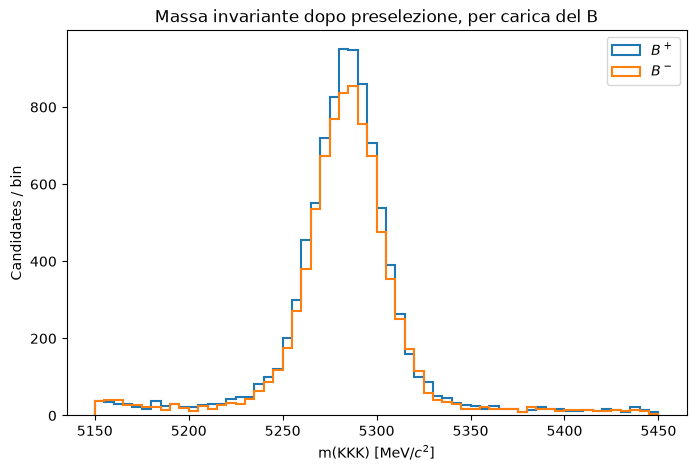

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
bins = np.linspace(bm.MASS_LO, bm.MASS_HI, 61)
ax.hist(m_obs[q_obs > 0], bins=bins, histtype="step", label=r"$B^+$", linewidth=1.5)
ax.hist(m_obs[q_obs < 0], bins=bins, histtype="step", label=r"$B^-$", linewidth=1.5)
ax.set_xlabel("m(KKK) [MeV/$c^2$]")
ax.set_ylabel("Candidates / bin")
ax.legend()
ax.set_title("Massa invariante dopo preselezione, per carica del B")
plt.show()

## Modello di massa e likelihood

$f(m) = N_s\,S(m;\mu,\sigma) + N_b\,B(m;\lambda)$, fit simultaneo con $N_s^+ = N_s(1-A)/2$, $N_s^- = N_s(1+A)/2$ (fondo diviso equamente tra le cariche, nessuna asimmetria di fondo modellata). Segnale = gaussiana troncata, fondo = esponenziale troncato, entrambi normalizzati su $[\mathrm{MASS\_LO}, \mathrm{MASS\_HI}]$. Implementazione in `bayesian_model.py` (`signal_pdf`, `background_pdf`, `log_likelihood`).

## Prior

Prior uniformi a bordi netti (idioma confermato nelle esercitazioni del corso: `0.0` dentro i bordi, `-np.inf` fuori — non HalfNormal). I bordi e il guess iniziale sono stati derivati da un primo sguardo ai dati reali (picco a ~5283 MeV, $N_s\approx 14300$, $N_b\approx 3550$ da una stima sideband vs finestra segnale), vedi `bayesian_model.PRIOR_BOUNDS` / `INITIAL_GUESS`.

In [6]:
for name in bm.PARAM_NAMES:
    lo, hi = bm.PRIOR_BOUNDS[name]
    print(f"{name:12s} bounds=({lo:.4g}, {hi:.4g})  guess={bm.INITIAL_GUESS[name]:.4g}")

theta0 = np.array([bm.INITIAL_GUESS[n] for n in bm.PARAM_NAMES])
lp0 = bm.log_posterior(theta0, m_obs, q_obs)
print("\nlog_posterior at initial guess:", lp0)
assert np.isfinite(lp0), 'initial guess falls outside the prior or gives zero likelihood'

N_s          bounds=(0, 8.92e+04)  guess=1.43e+04
N_b          bounds=(0, 8.92e+04)  guess=3550
A            bounds=(-1, 1)  guess=0
mu           bounds=(5260, 5310)  guess=5283
sigma        bounds=(3, 40)  guess=15
lambda_bkg   bounds=(1e-05, 0.05)  guess=0.0028

log_posterior at initial guess: 59666.50939435986


## Campionamento MCMC (emcee)

Walker inizializzati in una palla stretta attorno al guess iniziale (uno dei due schemi usati nelle esercitazioni del corso, l'altro essendo campionare uniformemente in tutto il box del prior — qui preferiamo la palla stretta per convergere più velocemente su un problema a 6 parametri).

In [7]:
ndim = len(theta0)
nwalkers = 32
nsteps = 9000

spread = np.array([
    0.03 * theta0[0],  # N_s
    0.05 * theta0[1],  # N_b
    0.05,               # A
    1.0,                 # mu
    1.0,                 # sigma
    0.15 * theta0[5],   # lambda_bkg
])
pos = theta0 + spread * np.random.default_rng(42).standard_normal((nwalkers, ndim))
pos[:, 2] = np.clip(pos[:, 2], -0.5, 0.5)  # keep A inside a sane starting range

sampler = emcee.EnsembleSampler(nwalkers, ndim, bm.log_posterior, args=(m_obs, q_obs))
sampler.run_mcmc(pos, nsteps, progress=True)
print("mean acceptance fraction:", np.mean(sampler.acceptance_fraction))

  0%|          | 0/9000 [00:00<?, ?it/s]

  0%|          | 4/9000 [00:00<04:04, 36.80it/s]

  0%|          | 8/9000 [00:00<04:15, 35.24it/s]

  0%|          | 12/9000 [00:00<04:23, 34.17it/s]

  0%|          | 16/9000 [00:00<04:31, 33.08it/s]

...

100%|█████████▉| 8995/9000 [04:37<00:00, 15.80it/s]

100%|█████████▉| 8997/9000 [04:37<00:00, 15.97it/s]

100%|█████████▉| 8999/9000 [04:37<00:00, 16.93it/s]

100%|██████████| 9000/9000 [04:38<00:00, 32.37it/s]

mean acceptance fraction: 0.5170868055555555


## Diagnostica di convergenza

**Non insegnata nel corso** (verificato: nessun notebook Week4 calcola autocorrelation time o mostra trace plot) — è un'estensione metodologica nostra, non ridondante con quanto fatto a lezione.

autocorrelation time per parametro:
  N_s          tau=76.7  (n_eff ~= 3755)
  N_b          tau=79.2  (n_eff ~= 3636)
  A            tau=71.2  (n_eff ~= 4046)
  mu           tau=60.8  (n_eff ~= 4740)
  sigma        tau=58.4  (n_eff ~= 4932)
  lambda_bkg   tau=70.1  (n_eff ~= 4108)


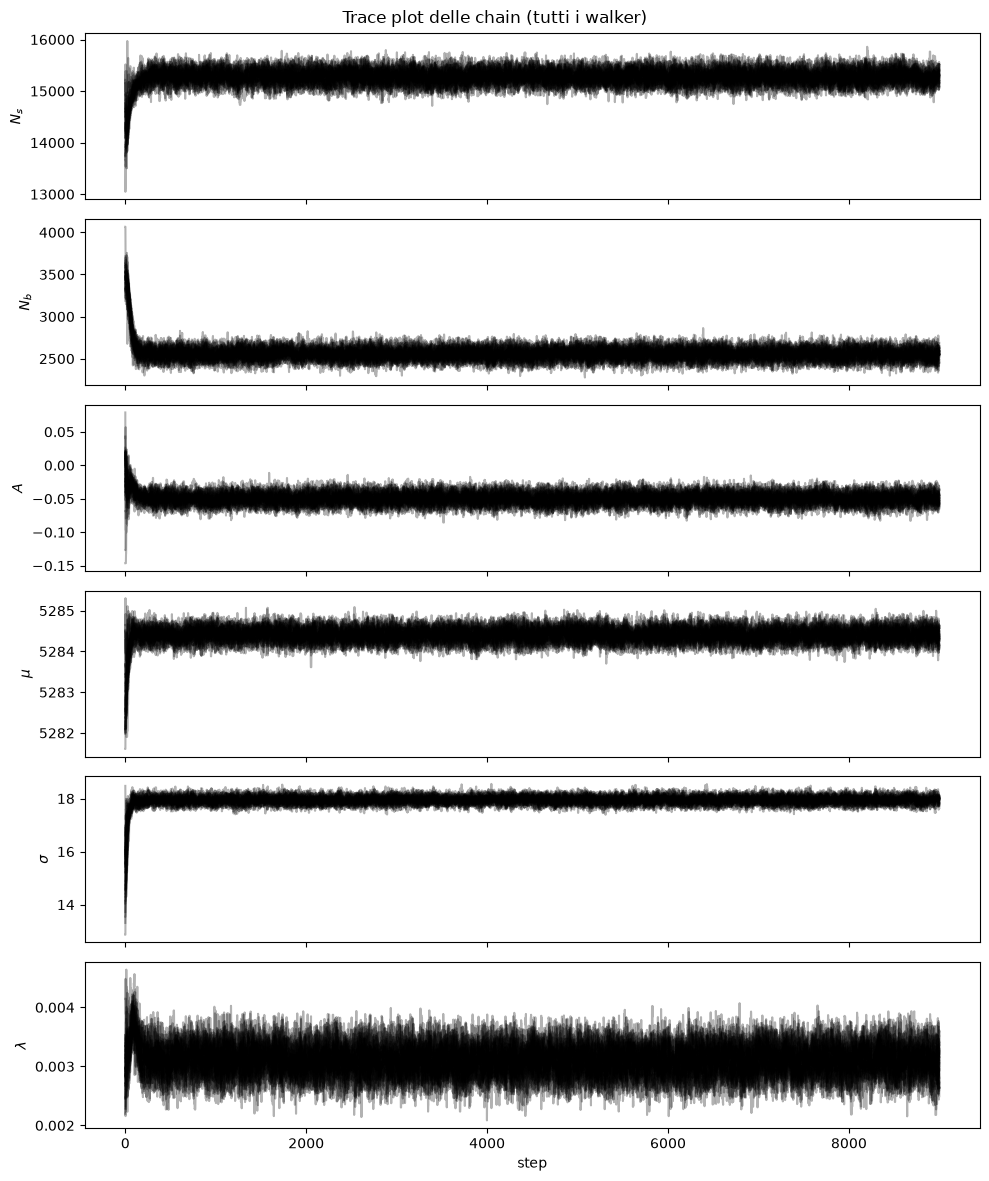

In [8]:
try:
    tau = sampler.get_autocorr_time()
    print("autocorrelation time per parametro:")
    for name, t in zip(bm.PARAM_NAMES, tau):
        print(f"  {name:12s} tau={t:.1f}  (n_eff ~= {nsteps*nwalkers/t:.0f})")
except emcee.autocorr.AutocorrError as e:
    print("Warning: catena forse troppo corta per una stima affidabile di tau:", e)

fig, axes = plt.subplots(ndim, figsize=(10, 12), sharex=True)
chain = sampler.get_chain()
for i in range(ndim):
    axes[i].plot(chain[:, :, i], alpha=0.3, color="k")
    axes[i].set_ylabel(bm.PARAM_LABELS[i])
axes[-1].set_xlabel("step")
fig.suptitle("Trace plot delle chain (tutti i walker)")
plt.tight_layout()
plt.show()

In [9]:
discard = nsteps // 6  # ~1/6 di burn-in, idioma confermato nelle esercitazioni del corso
flat_samples = sampler.get_chain(discard=discard, flat=True)
print(f"discarded first {discard} steps as burn-in, {len(flat_samples)} samples remaining")

discarded first 1500 steps as burn-in, 240000 samples remaining


## Output bayesiani

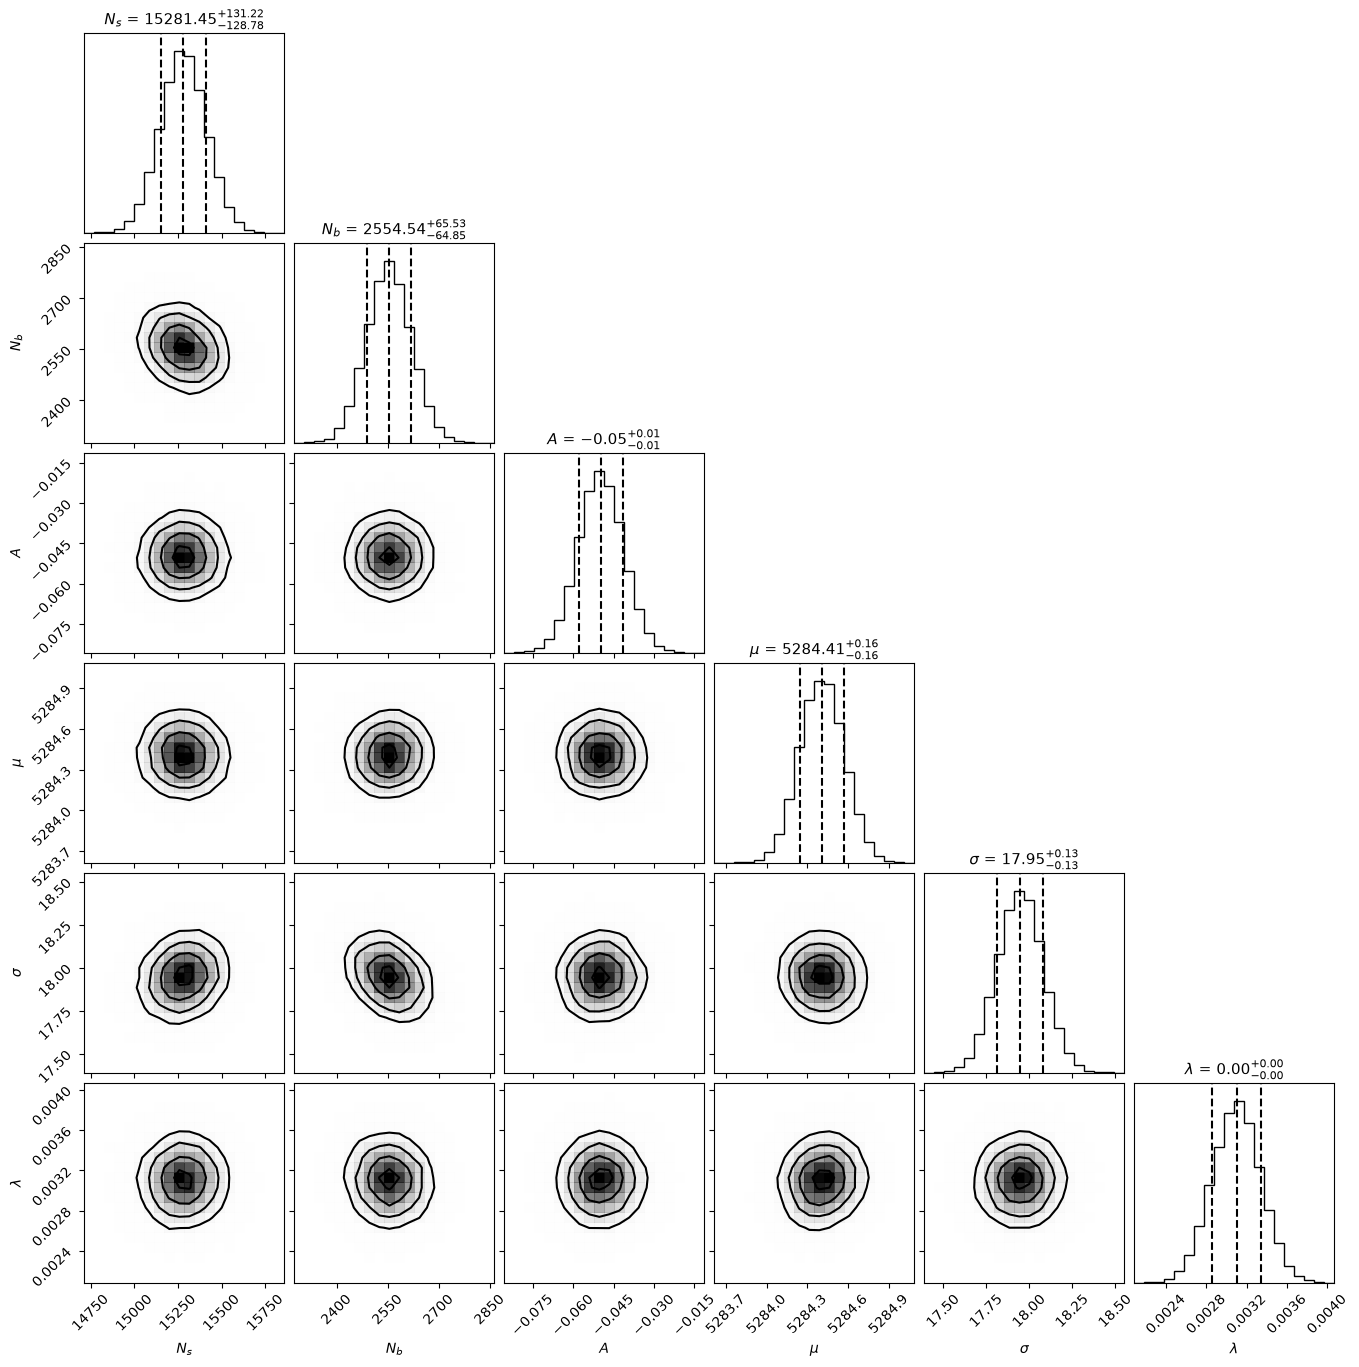

In [10]:
fig = corner.corner(
    flat_samples,
    labels=bm.PARAM_LABELS,
    quantiles=[0.16, 0.5, 0.84],
    show_titles=True,
    plot_datapoints=False,
    title_kwargs={"fontsize": 11},
)
plt.show()

In [11]:
A_samples = flat_samples[:, bm.PARAM_NAMES.index("A")]
A_median = np.median(A_samples)
ci68 = np.percentile(A_samples, [16, 84])
ci95 = np.percentile(A_samples, [2.5, 97.5])

print(f"A_raw (posterior median) = {A_median:.4f}")
print(f"  68% credible interval: [{ci68[0]:.4f}, {ci68[1]:.4f}]")
print(f"  95% credible interval: [{ci95[0]:.4f}, {ci95[1]:.4f}]")

A_raw (posterior median) = -0.0497
  68% credible interval: [-0.0579, -0.0413]
  95% credible interval: [-0.0659, -0.0331]


### Posterior predictive check

Curva del modello con i parametri al valore mediano del posterior, sovrapposta all'istogramma dei dati (separatamente per $B^+$ e $B^-$).

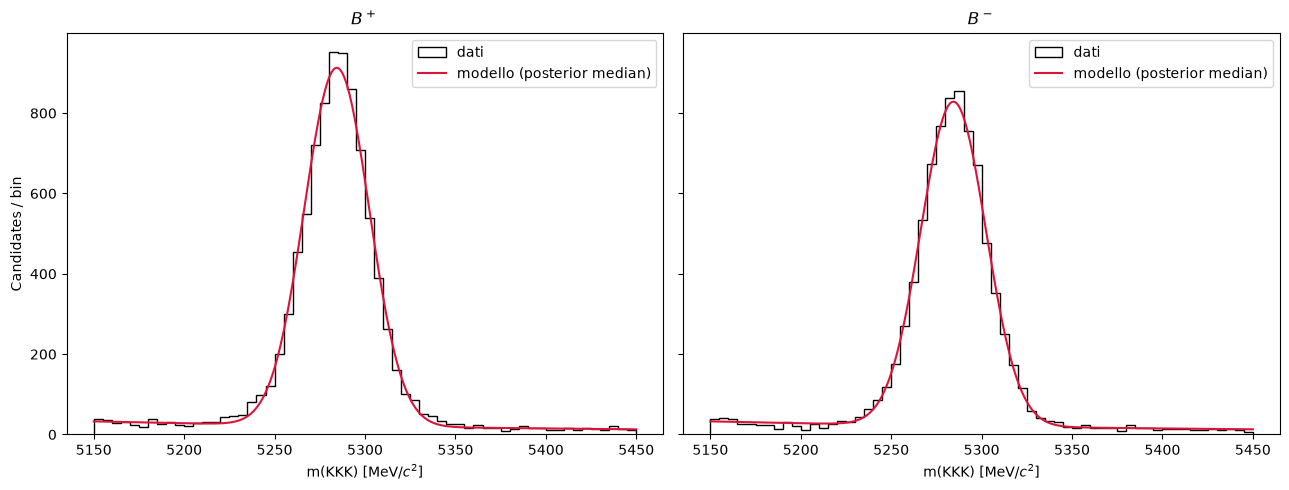

In [12]:
theta_med = np.median(flat_samples, axis=0)
N_s, N_b, A, mu, sigma, lam = theta_med
N_s_plus, N_s_minus, N_b_half = N_s*(1-A)/2, N_s*(1+A)/2, N_b/2

m_grid = np.linspace(bm.MASS_LO, bm.MASS_HI, 300)
bin_width = bins[1] - bins[0]

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, q_sign, N_s_q, label in (
    (axes[0], 1, N_s_plus, r"$B^+$"),
    (axes[1], -1, N_s_minus, r"$B^-$"),
):
    ax.hist(m_obs[q_obs == q_sign], bins=bins, histtype="step", color="k", label="dati")
    model_curve = (N_s_q * bm.signal_pdf(m_grid, mu, sigma) + N_b_half * bm.background_pdf(m_grid, lam)) * bin_width
    ax.plot(m_grid, model_curve, color="crimson", label="modello (posterior median)")
    ax.set_xlabel("m(KKK) [MeV/$c^2$]")
    ax.set_title(label)
    ax.legend()
axes[0].set_ylabel("Candidates / bin")
plt.tight_layout()
plt.show()

## Bayes factor: A = 0 vs A libero

Il metodo del corso (`Week4_BayesFactor.ipynb`) integra l'evidenza su una griglia 1D — non scala al nostro posterior a 6 parametri. Usiamo invece il **rapporto di Savage-Dickey**: $BF_{01} = p(A=0\mid\text{dati}) / \pi(A=0)$, stessa idea concettuale (rapporto di evidenze), adattata computazionalmente. La densità a posteriori in $A=0$ è stimata con una KDE sulla colonna $A$ della catena; la densità del prior è nota analiticamente ($1/2$, uniforme su $[-1,1]$). Assumiamo prior odds uguali fra $H_0$ ($A=0$) e $H_1$ ($A$ libero), quindi il Bayes factor coincide con gli odds a posteriori.

In [13]:
kde = gaussian_kde(A_samples)
posterior_density_at_0 = float(kde(0.0)[0])
prior_density_A = 1.0 / (bm.PRIOR_BOUNDS["A"][1] - bm.PRIOR_BOUNDS["A"][0])  # uniform prior density

BF_01 = posterior_density_at_0 / prior_density_A
print(f"posterior density of A at 0: {posterior_density_at_0:.3e}")
print(f"prior density of A at 0:     {prior_density_A:.4f}")
print(f"Savage-Dickey Bayes factor BF_01 (H0: A=0  vs  H1: A libero): {BF_01:.3e}")
print("(BF_01 > 1 favorisce H0/A=0; scala di Jeffreys: >3 evidenza moderata, >10 forte, >100 decisiva)")
n_sigma_away = abs(0.0 - A_median) / A_samples.std()
print()
print(f"A=0 e' a ~{n_sigma_away:.1f} deviazioni standard del posterior dal valore osservato:")
print("la KDE sta estrapolando molto in coda -> il valore esatto di BF_01 e' numericamente fragile,")
print("ma la conclusione qualitativa (evidenza estrema contro A=0) e' robusta.")

posterior density of A at 0: 1.607e-59
prior density of A at 0:     0.5000
Savage-Dickey Bayes factor BF_01 (H0: A=0  vs  H1: A libero): 3.214e-59
(BF_01 > 1 favorisce H0/A=0; scala di Jeffreys: >3 evidenza moderata, >10 forte, >100 decisiva)

A=0 e' a ~6.0 deviazioni standard del posterior dal valore osservato:
la KDE sta estrapolando molto in coda -> il valore esatto di BF_01 e' numericamente fragile,
ma la conclusione qualitativa (evidenza estrema contro A=0) e' robusta.


## Salvataggio risultati

Salvati in `results/` così il notebook di confronto finale (blocco 6 della pipeline) non deve rifare girare l'MCMC.

In [14]:
np.savez("results/mcmc_chain.npz", chain=sampler.get_chain(), flat_samples=flat_samples,
         discard=discard, param_names=bm.PARAM_NAMES)

summary = {
    "n_events_fit_window": int(len(m_obs)),
    "mass_window_MeV": [bm.MASS_LO, bm.MASS_HI],
    "A_raw_median": float(A_median),
    "A_raw_ci68": [float(ci68[0]), float(ci68[1])],
    "A_raw_ci95": [float(ci95[0]), float(ci95[1])],
    "bayes_factor_A0_vs_Afree": float(BF_01),
    "mean_acceptance_fraction": float(np.mean(sampler.acceptance_fraction)),
    "nwalkers": nwalkers, "nsteps": nsteps, "discard": discard,
}
with open("results/posterior_summary.json", "w") as f:
    _json.dump(summary, f, indent=2)

print(_json.dumps(summary, indent=2))

{
  "n_events_fit_window": 17839,
  "mass_window_MeV": [
    5150.0,
    5450.0
  ],
  "A_raw_median": -0.04972502482826961,
  "A_raw_ci68": [
    -0.05787008000900426,
    -0.04134353011281907
  ],
  "A_raw_ci95": [
    -0.06591755855055995,
    -0.03309108295283332
  ],
  "bayes_factor_A0_vs_Afree": 3.213500282495621e-59,
  "mean_acceptance_fraction": 0.5170868055555555,
  "nwalkers": 32,
  "nsteps": 9000,
  "discard": 1500
}


## Limiti noti e prossimi passi

- **Confronto con MLE/profile likelihood**: non ancora possibile, dipende dal fit frequentista di Marco (branch `freq`) sullo stesso modello di massa.
- **Finestra di massa** ristretta a [5150, 5450] MeV per evitare il rialzo di fondo sotto 5150 MeV (probabile contributo parzialmente ricostruito) — da rivedere insieme a Marco, e da includere nello studio sistematico sulla variazione della finestra.
- **Fondo diviso equamente fra le cariche** ($N_b/2$, $N_b/2$): assunzione di nessuna asimmetria di fondo, non validata.
- **Bayes factor via Savage-Dickey**: KDE con bandwidth di default (`scipy.stats.gaussian_kde`) — da controllare la sensibilità al bandwidth prima di fidarsi del numero.
- Toy-MC coverage check (validazione degli intervalli) ancora da fare, vedi proposta.